🚀 TensorFlow Version: 2.10.1
💻 Execution configured strictly on CPU.
✅ Montage configured with 27 standard motor/pre-motor channels.

--- Starting Systematic Quantitative Occlusion Evaluation ---

📂 Processing Dataset: Raw
Loaded 200 evaluation trials (100 Left, 100 Right).
-> Evaluating: eegnet_Raw_fold1.h5
   Baseline Acc: 91.50% | Top Channel: P4 (Drop: 24.00%)
-> Evaluating: cvt_Raw_fold1.h5
   Baseline Acc: 82.50% | Top Channel: C4 (Drop: 5.00%)
-> Evaluating: vit_pe_Raw_fold1.h5
   Baseline Acc: 83.00% | Top Channel: P4 (Drop: 10.00%)

📂 Processing Dataset: Filtered_8_30Hz
Loaded 200 evaluation trials (100 Left, 100 Right).
-> Evaluating: eegnet_Filtered_8_30Hz_fold1.h5
   Baseline Acc: 90.50% | Top Channel: P4 (Drop: 27.50%)
-> Evaluating: cvt_Filtered_8_30Hz_fold1.h5
   Baseline Acc: 84.50% | Top Channel: P4 (Drop: 21.50%)
-> Evaluating: vit_pe_Filtered_8_30Hz_fold1.h5
   Baseline Acc: 80.50% | Top Channel: CP3 (Drop: 12.00%)

📂 Processing Dataset: Filtered_8_13Hz
Loaded 200 ev

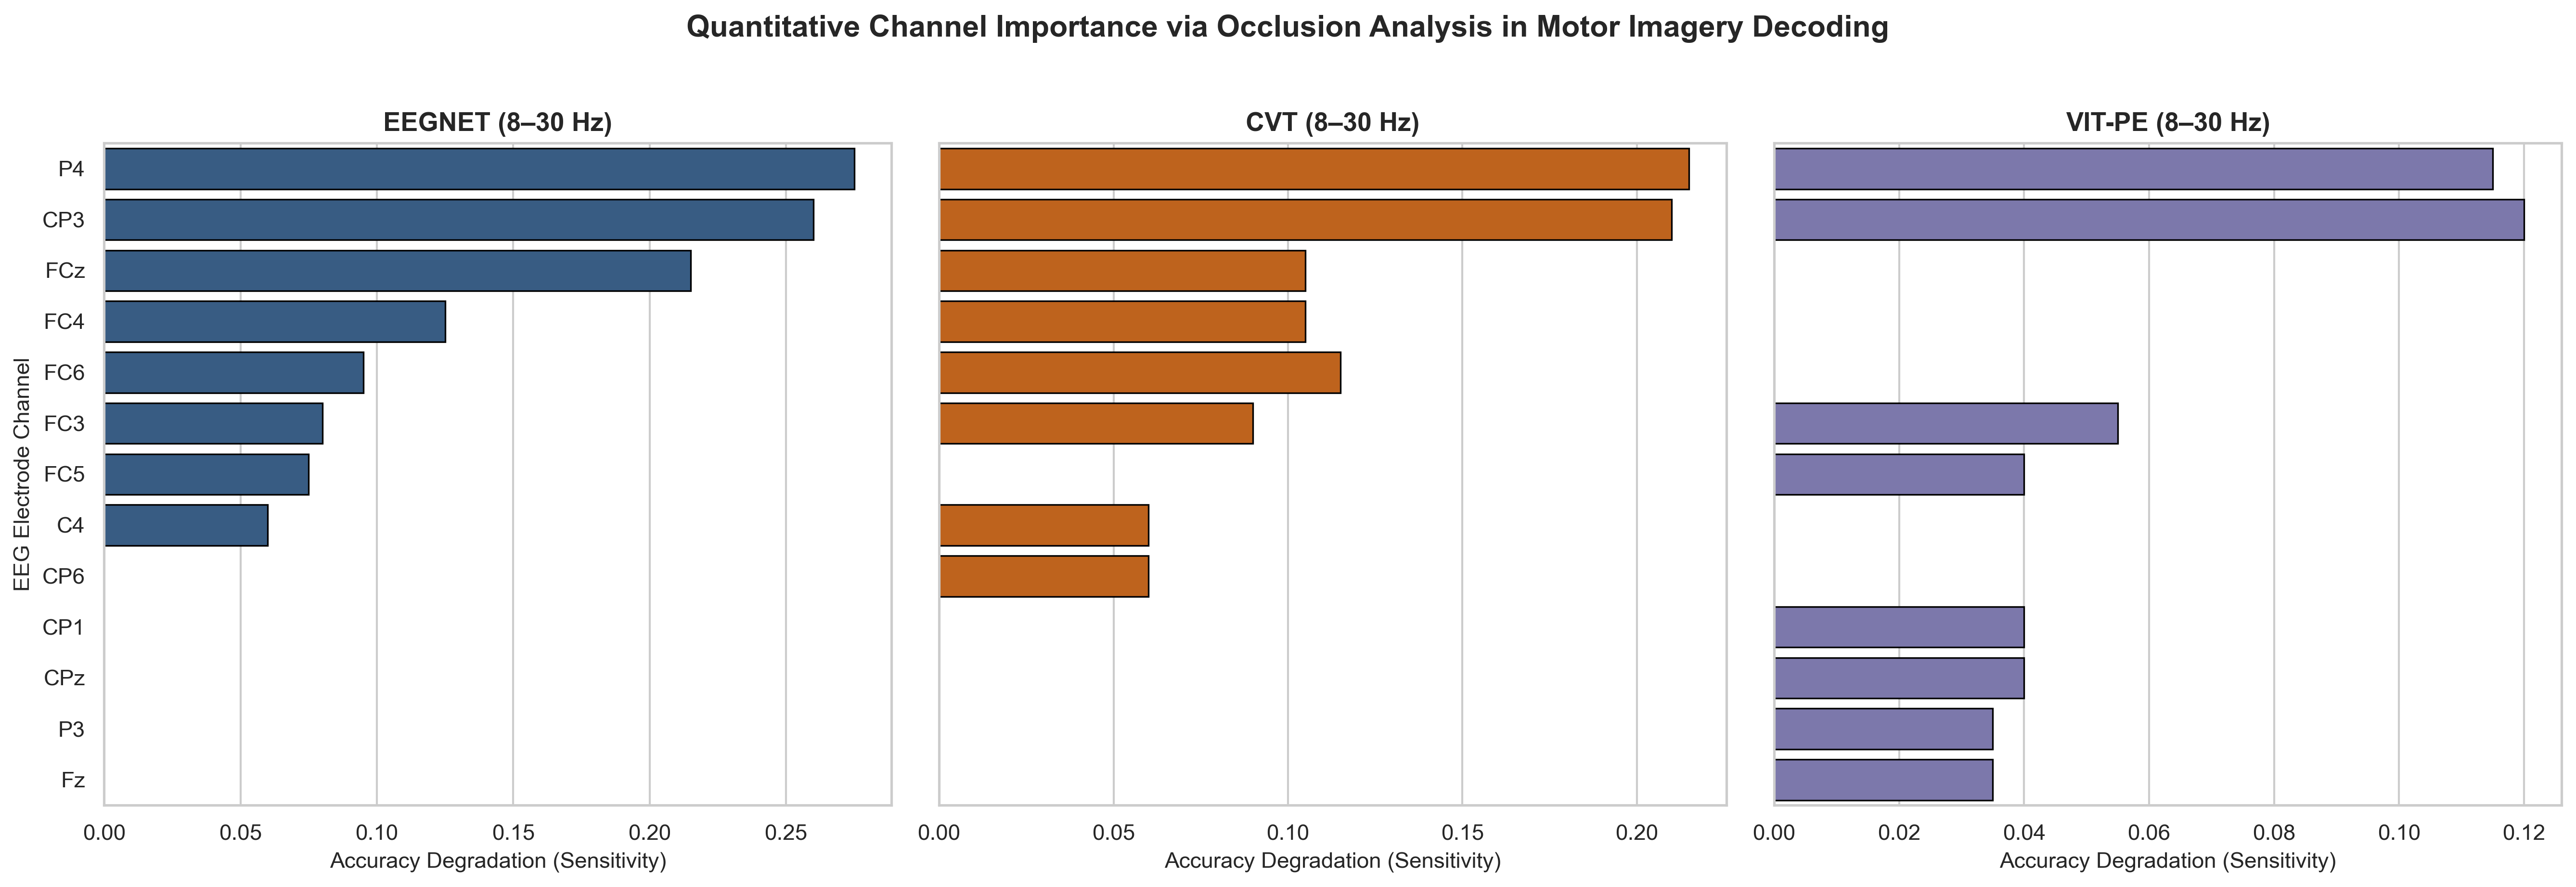

✅ Publication-ready figures exported successfully:


In [1]:
# ==============================================================================
# UNIFIED CHANNEL OCCLUSION XAI BENCHMARKING ENGINE
# Manuscript: JNEUMETH-D-26-00712 (Journal of Neuroscience Methods)
# ==============================================================================
import os
import gc
import glob
import random
import warnings
from pathlib import Path
from scipy.io import loadmat

# Force TensorFlow to run safely on CPU to prevent CuDNN driver crashes / VRAM OOM
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Layer

warnings.filterwarnings("ignore")

# Global Plotting Configuration (Journal Standards)
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "figure.dpi": 300
})
sns.set_theme(style="whitegrid", palette="muted")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"🚀 TensorFlow Version: {tf.__version__}")
print("💻 Execution configured strictly on CPU.")

# ==============================================================================
# 1. 27-CHANNEL MONTAGE CONFIGURATION (Motor Imagery Standard)
# ==============================================================================
CHANNEL_NAMES = [
    'F3', 'Fz', 'F4', 
    'FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 
    'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 
    'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 
    'P3', 'Pz', 'P4'
]
print(f"✅ Montage configured with {len(CHANNEL_NAMES)} standard motor/pre-motor channels.")

# ==============================================================================
# 2. VERIFIED CUSTOM LAYERS (Exact Weight Dimension Match)
# ==============================================================================
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        num_channels = signals.shape[-1]
        if num_channels is None:
            num_channels = tf.shape(signals)[-1]
        return tf.reshape(signals, [batch_size, -1, self.patch_size, num_channels])

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config


class PatchEncoder(Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.projection = tf.keras.layers.Dense(units=projection_dim)

    def build(self, input_shape):
        positions = np.arange(self.num_patches)[:, np.newaxis]
        dims = np.arange(self.projection_dim)[np.newaxis, :]
        angle_rates = 1 / np.power(10000, (2 * (dims // 2)) / np.float32(self.projection_dim))
        angle_rads = positions * angle_rates
        pos_encoding = np.zeros((self.num_patches, self.projection_dim), dtype=np.float32)
        pos_encoding[:, 0::2] = np.sin(angle_rads[:, 0::2])
        pos_encoding[:, 1::2] = np.cos(angle_rads[:, 1::2])
        
        self.position_embedding = tf.Variable(
            initial_value=pos_encoding,
            trainable=False,
            name="pos_embedding"
        )
        super().build(input_shape)

    def call(self, patch):
        batch_size = tf.shape(patch)[0]
        feature_dim = patch.shape[-2] * patch.shape[-1] if (patch.shape[-2] is not None and patch.shape[-1] is not None) else -1
        flattened = tf.reshape(patch, [batch_size, self.num_patches, feature_dim])
        return self.projection(flattened) + self.position_embedding

    def get_config(self):
        config = super().get_config()
        config.update({
            "num_patches": self.num_patches,
            "projection_dim": self.projection_dim
        })
        return config


class SinusoidalPositionEmbedding(Layer):
    def __init__(self, sequence_length=None, dim=None, embedding_dim=None, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.dim = dim if dim is not None else embedding_dim
        self.embedding_dim = self.dim

    def build(self, input_shape):
        if self.sequence_length is None:
            self.sequence_length = input_shape[1]
        if self.dim is None:
            self.dim = input_shape[-1]
            self.embedding_dim = self.dim
            
        pos = np.arange(self.sequence_length)[:, np.newaxis]
        i = np.arange(self.dim)[np.newaxis, :]
        angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(self.dim))
        angle_rads = pos * angle_rates
        pos_encoding = np.zeros((1, self.sequence_length, self.dim), dtype=np.float32)
        pos_encoding[0, :, 0::2] = np.sin(angle_rads[:, 0::2])
        pos_encoding[0, :, 1::2] = np.cos(angle_rads[:, 1::2])
        
        self.pos_encoding = tf.constant(pos_encoding)
        super().build(input_shape)

    def call(self, inputs):
        return inputs + self.pos_encoding

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "dim": self.dim,
            "embedding_dim": self.dim
        })
        return config


CUSTOM_OBJECTS = {
    "Patches": Patches,
    "PatchEncoder": PatchEncoder,
    "SinusoidalPositionEmbedding": SinusoidalPositionEmbedding
}

# ==============================================================================
# 3. ROBUST PATH DETECTION (Article + Sibling MI BCI Directory)
# ==============================================================================
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "Analysis").is_dir() and (candidate / "results").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate project root containing 'Analysis' and 'results'.")

PROJECT_ROOT = find_project_root()
ANALYSIS_DIR = PROJECT_ROOT / "Analysis"
OUTPUT_DIR = ANALYSIS_DIR / "xai_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Candidate paths for models (.h5)
possible_model_dirs = [
    PROJECT_ROOT / "models",
    PROJECT_ROOT / "Models",
    PROJECT_ROOT.parent / "MI BCI" / "models",
    PROJECT_ROOT.parent / "models"
]
MODELS_DIR = next((d for d in possible_model_dirs if d.is_dir() and any(d.glob("*.h5"))), None)
if MODELS_DIR is None:
    raise FileNotFoundError("No .h5 model checkpoints found in candidates!")

DATASET_NAMES = ["Raw", "Filtered_8_30Hz", "Filtered_8_13Hz"]
DATA_DIRS = {}
for ds_name in DATASET_NAMES:
    candidates = [
        PROJECT_ROOT / ds_name,
        PROJECT_ROOT.parent / "MI BCI" / ds_name,
        PROJECT_ROOT.parent / ds_name,
        PROJECT_ROOT / "data" / ds_name
    ]
    resolved = next((d for d in candidates if d.is_dir() and any(d.glob("**/*.npy"))), None)
    if resolved is None:
        raise FileNotFoundError(f"Dataset folder '{ds_name}' containing .npy files not found!")
    DATA_DIRS[ds_name] = resolved

print(f"📁 Project Root: {PROJECT_ROOT}")
print(f"📁 Models Dir:   {MODELS_DIR}")
for ds, p in DATA_DIRS.items():
    print(f"📁 Dataset [{ds}]: {p}")

# ==============================================================================
# 4. BALANCED EVALUATION SUBSET LOADER
# ==============================================================================
def load_evaluation_subset(dataset_dir, samples_per_class=100):
    left_files = []
    right_files = []

    for root, _, files in os.walk(dataset_dir):
        for file in files:
            if file.endswith(".npy"):
                full_path = os.path.join(root, file)
                if "left" in file.lower():
                    left_files.append(full_path)
                else:
                    right_files.append(full_path)

    if not left_files or not right_files:
        raise ValueError(f"Insufficient .npy files in {dataset_dir} (Left: {len(left_files)}, Right: {len(right_files)})")

    rng = random.Random(SEED)
    rng.shuffle(left_files)
    rng.shuffle(right_files)

    selected_left = left_files[:samples_per_class]
    selected_right = right_files[:samples_per_class]

    selected_files = selected_left + selected_right
    labels = [0] * len(selected_left) + [1] * len(selected_right)

    combined = list(zip(selected_files, labels))
    rng.shuffle(combined)
    selected_files, labels = zip(*combined)

    trials = []
    for f in selected_files:
        arr = np.load(f)
        if arr.shape[0] != len(CHANNEL_NAMES) and arr.shape[1] == len(CHANNEL_NAMES):
            arr = arr.T
        trials.append(arr)

    X_base = np.array(trials, dtype=np.float32)  # (N, 27, 2560)
    y_true = np.array(labels, dtype=np.int32)
    return X_base, y_true

# ==============================================================================
# 5. PERTURBATION ENGINE (Channel Occlusion Sensitivity)
# ==============================================================================
def format_tensor_for_architecture(X_base, arch_name):
    if "eegnet" in arch_name.lower():
        return np.expand_dims(X_base, axis=-1)  # (N, 27, 2560, 1)
    else:
        return np.transpose(X_base, (0, 2, 1))   # (N, 2560, 27)

def evaluate_channel_occlusion(model, X_base, y_true, arch_name, channel_names):
    with tf.device('/CPU:0'):
        X_input = format_tensor_for_architecture(X_base, arch_name)
        preds = model.predict(X_input, batch_size=32, verbose=0)
        
        if preds.ndim > 1 and preds.shape[-1] > 1:
            y_pred = np.argmax(preds, axis=-1)
        else:
            y_pred = (preds > 0.5).astype(int).flatten()
            
        baseline_acc = float(np.mean(y_pred == y_true))
        results = []

        for ch_idx, ch_name in enumerate(channel_names):
            X_perturbed = X_base.copy()
            X_perturbed[:, ch_idx, :] = 0.0  # Zero-out electrode

            X_pert_input = format_tensor_for_architecture(X_perturbed, arch_name)
            preds_pert = model.predict(X_pert_input, batch_size=32, verbose=0)
            
            if preds_pert.ndim > 1 and preds_pert.shape[-1] > 1:
                y_pred_pert = np.argmax(preds_pert, axis=-1)
            else:
                y_pred_pert = (preds_pert > 0.5).astype(int).flatten()
                
            pert_acc = float(np.mean(y_pred_pert == y_true))
            acc_drop = baseline_acc - pert_acc

            results.append({
                "Channel_Index": ch_idx,
                "Channel": ch_name,
                "Baseline_Acc": baseline_acc,
                "Occluded_Acc": pert_acc,
                "Accuracy_Drop": max(0.0, acc_drop)
            })

    df = pd.DataFrame(results)
    df = df.sort_values(by="Accuracy_Drop", ascending=False).reset_index(drop=True)
    return df, baseline_acc

# ==============================================================================
# 6. RUN BENCHMARK EXPERIMENTS ACROSS ALL ARCHITECTURES & BANDS
# ==============================================================================
architectures = ["eegnet", "cvt", "vit_pe"]
datasets = ["Raw", "Filtered_8_30Hz", "Filtered_8_13Hz"]
all_importance_records = []

print("\n--- Starting Systematic Quantitative Occlusion Evaluation ---")

for ds_name in datasets:
    ds_dir = DATA_DIRS[ds_name]
    print(f"\n📂 Processing Dataset: {ds_name}")
    X_eval, y_eval = load_evaluation_subset(ds_dir, samples_per_class=100)
    print(f"Loaded {len(y_eval)} evaluation trials ({np.sum(y_eval==0)} Left, {np.sum(y_eval==1)} Right).")

    for arch in architectures:
        pattern = os.path.join(MODELS_DIR, f"*{arch}*{ds_name}*fold1*.h5")
        matches = glob.glob(pattern)
        if not matches:
            pattern = os.path.join(MODELS_DIR, f"*{arch}*{ds_name}*.h5")
            matches = glob.glob(pattern)

        if not matches:
            print(f"⚠️ [Warning] No model found for {arch} - {ds_name}. Skipping.")
            continue

        model_path = matches[0]
        model_name = os.path.basename(model_path)
        print(f"-> Evaluating: {model_name}")

        try:
            model = load_model(model_path, custom_objects=CUSTOM_OBJECTS, compile=False)
            df_imp, base_acc = evaluate_channel_occlusion(
                model=model,
                X_base=X_eval,
                y_true=y_eval,
                arch_name=arch,
                channel_names=CHANNEL_NAMES
            )
            print(f"   Baseline Acc: {base_acc*100:.2f}% | Top Channel: {df_imp.iloc[0]['Channel']} (Drop: {df_imp.iloc[0]['Accuracy_Drop']*100:.2f}%)")

            df_imp["Architecture"] = arch.upper().replace("_", "-")
            df_imp["Dataset"] = ds_name
            all_importance_records.append(df_imp)

            del model
            tf.keras.backend.clear_session()
            gc.collect()

        except Exception as e:
            print(f"❌ [Error] Failed on {model_name}: {e}")

# Aggregate and save CSV summary
full_importance_df = pd.concat(all_importance_records, ignore_index=True)
summary_csv_path = OUTPUT_DIR / "channel_occlusion_importance_summary.csv"
full_importance_df.to_csv(summary_csv_path, index=False)
print(f"\n✅ Occlusion summary metrics saved to: {summary_csv_path}")

# ==============================================================================
# 7. PUBLICATION-QUALITY MULTI-PANEL FIGURE GENERATION
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
arch_list = ["EEGNET", "CVT", "VIT-PE"]
colors = ["#2b5c8f", "#d95f02", "#7570b3"]

# Focus on Filtered 8-30Hz (Mu/Beta bands, primary for Motor Imagery)
target_dataset = "Filtered_8_30Hz"
subset_df = full_importance_df[full_importance_df["Dataset"] == target_dataset]

for idx, (arch, color) in enumerate(zip(arch_list, colors)):
    ax = axes[idx]
    arch_data = subset_df[subset_df["Architecture"] == arch].head(8)
    
    sns.barplot(
        data=arch_data,
        x="Accuracy_Drop",
        y="Channel",
        ax=ax,
        color=color,
        edgecolor="black",
        linewidth=0.8
    )
    
    ax.set_title(f"{arch} (8–30 Hz)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Accuracy Degradation (Sensitivity)", fontsize=11)
    if idx == 0:
        ax.set_ylabel("EEG Electrode Channel", fontsize=11)
    else:
        ax.set_ylabel("")

plt.suptitle(
    "Quantitative Channel Importance via Occlusion Analysis in Motor Imagery Decoding",
    fontsize=15,
    fontweight="bold",
    y=1.02
)
plt.tight_layout()

png_path = OUTPUT_DIR / "channel_occlusion_comparison.png"
pdf_path = OUTPUT_DIR / "channel_occlusion_comparison.pdf"
plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(pdf_path, format="pdf", bbox_inches="tight")

plt.show()
print(f"✅ Publication-ready figures exported successfully:")
print(f"   PNG (300 DPI): {png_path}")
print(f"   PDF (Vector):  {pdf_path}")